## Info

* data source: HGNC & ChEMBL

## data process

In [ ]:
import pandas as pd

ref_df = pd.read_csv('../UniPert/data/processed_target_info_hgnc19321.csv').drop_duplicates()
ref_df.rename(columns={'UniProt accession': 'UniProt Accessions'}, inplace=True)
ref_df.dropna(subset=['UniProt Accessions'], inplace=True)
len(ref_df)

19305

In [ ]:
import pandas as pd

pc_df = pd.read_csv('../UniPert/data/processed_CHEMBL_single_protein_target_annotations.csv').drop_duplicates()
len(pc_df)

4389

In [5]:
pc_df = pc_df.merge(ref_df, on='UniProt Accessions', how='outer')
len(pc_df)

19443

In [ ]:
import pickle

file_path = '../UniPert/current_model/unipert_reps.pkl'

with open(file_path, 'rb') as f:
    try:
        reps = pickle.load(f)
    except Exception as e:
        print(f"Error reading pickle file: {str(e)}")

In [6]:
new_acc = list(set(pc_df['UniProt Accessions'].tolist()) - set(reps.keys()))
len(new_acc)

0

## add_tsne_features_to_df func

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

def add_tsne_features_to_df(pc_df, unipert_reps, perplexity=30):
    features = []
    for uid in pc_df['UniProt Accessions']:
        features.append(unipert_reps[uid])
    features = np.array(features)
    
    tsne = TSNE(
        n_components=2, 
        perplexity=perplexity,
        early_exaggeration=12,
        learning_rate=200,
        random_state=42
        )
    tsne_result = tsne.fit_transform(features)

    pc_df['t-SNE_1'] = tsne_result[:, 0]
    pc_df['t-SNE_2'] = tsne_result[:, 1]
    
    return pc_df


## define clustering metrics 

In [8]:
metric_df = pd.DataFrame({'level':[],
                          'class':[],
                          'ARI':[],
                          'NMI':[],})
metric_df

,level,class,ARI,NMI


## tsne plot

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pypalettes import load_cmap

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])


### protein_classification_level_1

In [10]:
level_1_df = pc_df.dropna(subset=['protein_classification_level_1'])
len(level_1_df)

4417

In [11]:
level = 5

top_cat = level_1_df[f'protein_classification_level_{level}'].value_counts().values

group_counts = level_1_df.loc[:, [f'protein_classification_level_{level}', f'protein_classification_level_{level+1}']] \
    .groupby([f'protein_classification_level_{level}', f'protein_classification_level_{level+1}']).size()

result_df = group_counts.reset_index()
result_df.columns = [f'Parent Class Name', f'Child Class Name', '#Chile Class Members']

desired_order = list(level_1_df[f'protein_classification_level_{level}'].value_counts().index)
order_dict = {cat: i for i, cat in enumerate(desired_order)}
result_df['sort_order'] = result_df[f'Parent Class Name'].map(order_dict)
result_df = result_df.sort_values(['#Chile Class Members'], ascending=False).reset_index(drop=True)
result_df = result_df.sort_values(['sort_order', '#Chile Class Members'], ascending=[True, False]).reset_index(drop=True)
result_df = result_df.drop(columns=['sort_order'])
result_df['Parent Class Level'] = level

result_df

,Parent Class Name,Child Class Name,#Chile Class Members,Parent Class Level
0,STE protein kinase STE20 family,STE protein kinase KHS subfamily,4,5
1,STE protein kinase STE20 family,STE protein kinase YSK subfamily,3,5
2,STE protein kinase STE20 family,STE protein kinase PAKA subfamily,3,5
3,STE protein kinase STE20 family,STE protein kinase PAKB subfamily,3,5
4,STE protein kinase STE20 family,STE protein kinase TAO subfamily,3,5
...,...,...,...,...
81,AGC protein kinase RSK family,AGC protein kinase p70 subfamily,2,5
82,CMGC protein kinase RCK family,CMGC protein kinase MAK,2,5
83,Aspartic protease A22A subfamily,Aspartic protease A22A regulatory subfamily,1,5
84,Metallo protease M67 family,Metallo protease M67A subfamily,1,5


In [12]:
level_1_df_with_tsne = add_tsne_features_to_df(level_1_df, reps)

/tmp/ipykernel_1975986/1927192028.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pc_df['t-SNE_1'] = tsne_result[:, 0]
/tmp/ipykernel_1975986/1927192028.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pc_df['t-SNE_2'] = tsne_result[:, 1]


In [13]:
df=level_1_df_with_tsne
category_col='protein_classification_level_1'
topk=7
default_classes = ['Unclassified protein']


In [14]:
categories = list(df['protein_classification_level_1'].value_counts().index)
counts = pc_df[category_col].value_counts().reindex(categories).fillna(0)

result_df = pd.DataFrame({
    'Category': counts.index,
    'Count': counts.values
})

result_df

,Category,Count
0,Enzyme,2093
1,Unclassified protein,751
2,Membrane receptor,492
3,Epigenetic regulator,212
4,Transporter,177
5,Ion channel,174
6,Transcription factor,142
7,Secreted protein,140
8,Other cytosolic protein,91
9,Other nuclear protein,45


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

categories = list(df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(categories)

select_df = df[df[category_col].isin(categories)]
select_pros = list(select_df['UniProt Accessions'])
labels_true = list(select_df[category_col])
X = [reps[x] for x in select_pros]

n_class = len(categories)
kmeans = KMeans(n_clusters=n_class, random_state=0).fit(X)
labels_pred = kmeans.labels_

ari_score = adjusted_rand_score(labels_true, labels_pred)
nmi_score = normalized_mutual_info_score(labels_true, labels_pred)

print(f'Adjusted Rand Index (ARI): {ari_score}')
print(f'Normalized Mutual Information (NMI): {nmi_score}')

['Enzyme', 'Membrane receptor', 'Epigenetic regulator', 'Transporter', 'Ion channel', 'Transcription factor', 'Secreted protein']
Adjusted Rand Index (ARI): 0.25446284261242397
Normalized Mutual Information (NMI): 0.29520389379249146


In [25]:
metric_df = pd.concat([metric_df, pd.DataFrame({
    'level': [1],
    'class': ['target'],
    'ARI': [ari_score],
    'NMI': [nmi_score]
})], ignore_index=True)

In [26]:
metric_df

,level,class,ARI,NMI
0,1.0,target,0.254463,0.295204


Current font settings: ['Helvetica']
['Enzyme', 'Membrane receptor', 'Epigenetic regulator', 'Transporter', 'Ion channel', 'Transcription factor', 'Secreted protein']


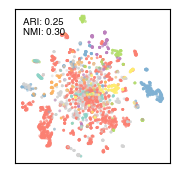

In [ ]:
plt.figure(figsize=(2, 2))

df = df.reset_index(drop=True)

categories = list(df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(categories)
palette = sns.color_palette(['#fb8072', '#80b1d3', '#ffed6f','#b3de69', '#bc80bd','#8dd3c7', '#fdb462'])
category_to_color = {category: color for category, color in zip(categories, palette)}
df['color'] = df.apply(lambda row: category_to_color.get(row[category_col], 'lightgrey'), axis=1)

ranked_category = list(df[category_col].value_counts().index)
df['plot rank'] = [0 if (x in default_classes) else 1+ranked_category.index(x) for x in list(df[category_col])]
df = df.sort_values(by=['plot rank']) 

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_edgecolor('black') 
    spine.set_linewidth(0.8)      

plt.scatter(df['t-SNE_1'], 
            df['t-SNE_2'], 
            c=df['color'], 
            alpha=0.5, 
            s=4, 
            linewidths=0.0,
            )

plt.title('', fontsize=12)
plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0) 
plt.tick_params(axis='y', which='both', pad=0) 
plt.xlabel('', fontsize=9, labelpad=-1)
plt.ylabel('', fontsize=9, labelpad=-4)


plt.text(0.05, 0.95, 
         f'ARI: {ari_score:.2f}\nNMI: {nmi_score:.2f}', 
         transform=plt.gca().transAxes, 
         fontsize=7, 
         fontweight='normal',
         verticalalignment='top', 
         )

plt.show()

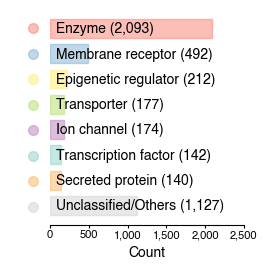

In [25]:
bar_width = 0.75
counts = pc_df[category_col].value_counts().reindex(categories).fillna(0)
counts['Unclassified/Others'] = level_1_df_with_tsne[category_col].value_counts()[7:].sum()+751
categories = list(counts.index)
bar_y = np.arange(len(categories))


fig, ax = plt.subplots(figsize=(2.5, 2.8)) 
palette = sns.color_palette(['#fb8072', '#80b1d3', '#ffed6f','#b3de69', '#bc80bd','#8dd3c7', '#fdb462', 'lightgray'])

ax.barh(bar_y, 
        counts, 
        color=palette, 
        edgecolor=palette, 
        height=bar_width,
        fill=True,
        alpha=0.5,
        zorder=0
        )

ax.set_yticks(bar_y)
ylabels = [cat+f' ({int(count):,})' for cat, count in zip(categories, counts)]
ax.set_yticklabels(ylabels, fontsize=10, va='center', ha='left', zorder=1)
for i, label in enumerate(ax.get_yticklabels()):
    label.set_x(0.08)  
ax.tick_params(axis='x', width=0.8, length=2, color='black', pad=5)
ax.set_xticks([0, 500, 1000, 1500, 2000, 2500])
ax.set_xticklabels(['0', '500', '1,000', '1,500', '2,000', '2,500'], fontsize=8, rotation=0, va='center', ha='center', zorder=2)
ax.set_xlabel('Count', fontdict={'fontsize': 10})
ax.invert_yaxis()  

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='both',    
                which='both',  
                top=False,     
                left=False,     
                right=False)    
ax.spines['bottom'].set_linewidth(0.8)


handles = []
labels = []
for category, color in zip(categories, palette):
    handles.append(plt.Line2D([0], [0], color=color, marker='o', linestyle='None', markersize=7, alpha=0.5))
    labels.append('')

plt.legend(handles, 
            labels, 
            loc='center left', 
            bbox_to_anchor=(-0.25, 0, 0, 0.98), 
            fontsize=12,
            edgecolor='none',
            facecolor='none',
            handletextpad=0,
            handleheight=1.2,
            handlelength=2,
            )

title = ax.set_title('', fontsize=10, fontweight='bold')
title.set_position([0.45, 1.0])

plt.show()

### protein_classification_level_2

In [26]:
### level 2 preprocessing

# Phosphodiesterase belong to Hydrolase
# Protease belong to Hydrolase
# Phosphatase belong to Hydrolase
# Aminoacyltransferase belong to Transferase

for i, row in pc_df.iterrows():
    level2 = pc_df.loc[i, f'protein_classification_level_2']
    if level2 in ['Phosphodiesterase', 'Protease', 'Phosphatase']:
        pc_df.loc[i, f'protein_classification_level_2'] = 'Hydrolase'
    elif level2 in ['Aminoacyltransferase']:
        pc_df.loc[i, f'protein_classification_level_2'] = 'Transferase'
    else:
        pass

In [27]:
level = 2
category_col = f'protein_classification_level_{level}'

query_class = []
for category in list(pc_df[f'protein_classification_level_{level-1}'].value_counts().index):
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category]
    if len(subset)>30 and (len(subset[f'protein_classification_level_{level}'].value_counts())>1):
        query_class.append(category)

print(query_class)

['Enzyme', 'Membrane receptor', 'Epigenetic regulator', 'Transporter', 'Ion channel']


In [28]:
categories = list(df[f'protein_classification_level_{level}'].value_counts().index)
counts = pc_df[category_col].value_counts().reindex(categories).fillna(0)

result_df = pd.DataFrame({
    'Category': counts.index,
    'Count': counts.values
})

result_df

,Category,Count
0,Kinase,451.0
1,Transferase,388.0
2,Hydrolase,706.0
3,Family A G protein-coupled receptor,278.0
4,Oxidoreductase,231.0
5,Protease,0.0
6,Reader,151.0
7,Electrochemical transporter,121.0
8,Phosphatase,0.0
9,Voltage-gated ion channel,93.0


Current font settings: ['Helvetica']
Enzyme
['Hydrolase', 'Kinase', 'Transferase', 'Oxidoreductase', 'Lyase', 'Ligase', 'Isomerase', 'Cytochrome P450']


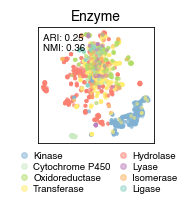

Membrane receptor
['Family A G protein-coupled receptor', 'Family B G protein-coupled receptor', 'Taste family G protein-coupled receptor', 'Family C G protein-coupled receptor', 'Toll-like and Il-1 receptors', 'Frizzled family G protein-coupled receptor']


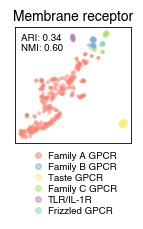

Epigenetic regulator
['Reader', 'Writer', 'Eraser']


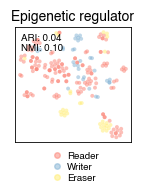

Transporter
['Electrochemical transporter', 'Primary active transporter', 'Transmembrane 1-electron transfer carriers', 'Group translocator']


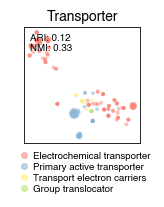

Ion channel
['Voltage-gated ion channel', 'Ligand-gated ion channel']


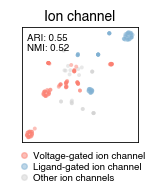

In [ ]:
cat_with_others = []
for category in query_class:
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    subset_with_tsne = add_tsne_features_to_df(subset, reps, perplexity=30)

    sub_categories = list(subset_with_tsne[category_col].value_counts().index)

    ## 过滤掉少数类别
    default_classes = ['Other ion channel']
    sub_categories_tmp = sub_categories
    for sub_cat in sub_categories_tmp:
        if sub_cat in default_classes:
            sub_categories.remove(sub_cat)
            cat_with_others.append(category)
    topk = None
    if topk is not None:  sub_categories = sub_categories[:topk]

    print(category)
    print(sub_categories)
    n_categories = len(sub_categories)

    palette = sns.color_palette(['#fb8072', '#80b1d3', '#ffed6f','#b3de69', '#bc80bd','#8dd3c7', '#fdb462', '#ccebc5', '#fccde5'])
    category_to_color = {category: color for category, color in zip(sub_categories, palette)}
    subset_with_tsne['color'] = subset_with_tsne.apply(lambda row: category_to_color.get(row[category_col], 'lightgrey'), axis=1)
    subset_with_tsne['plot rank'] = [0 if (x in default_classes) else 1+sub_categories.index(x) for x in list(subset_with_tsne[category_col])]
    subset_with_tsne = subset_with_tsne.sort_values(by=['plot rank']) 


    plt.figure(figsize=(1.5, 1.5))  
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')  
        spine.set_linewidth(0.6)      
    plt.scatter(
            subset_with_tsne['t-SNE_1'], 
            subset_with_tsne['t-SNE_2'], 
            c=subset_with_tsne['color'], 
            alpha=0.5, 
            s=8, 
            linewidths=0.0,
            )
    
    handles = []
    labels = []
    abbrs = {
        "Family A G protein-coupled receptor": "Family A GPCR",
        "Family B G protein-coupled receptor": "Family B GPCR",
        "Taste family G protein-coupled receptor": "Taste GPCR",
        "Family C G protein-coupled receptor": "Family C GPCR",
        "Toll-like and Il-1 receptors": "TLR/IL-1R",
        "Frizzled family G protein-coupled receptor": "Frizzled GPCR",
        "Transmembrane 1-electron transfer carriers": "Transport electron carriers"
    }
    zipped = list(zip(sub_categories, palette))
    if category == 'Enzyme':
        new_order = ['Kinase', 
                     'Cytochrome P450',
                     'Oxidoreductase', 
                     'Transferase', 
                     'Hydrolase', 
                     'Lyase', 
                     'Isomerase',
                     'Ligase', 
                     ]
        new_zipped = [zipped[i] for i in [sub_categories.index(cat) for cat in new_order]]
    else:
        new_zipped = zipped
    for cat, color in new_zipped:
        if cat in abbrs.keys():
            cat = abbrs[cat]
        handles.append(plt.Line2D([0], [0], 
                                  color=color, 
                                  marker='o', 
                                  linestyle='None', 
                                  linewidth=0.0,
                                  alpha=0.5,
                                  markersize=4,
                                  ))
        labels.append(cat)
    if category in cat_with_others:
        handles.append(plt.Line2D([0], [0], 
                                    color='lightgrey', 
                                    marker='o', 
                                    linestyle='None', 
                                    linewidth=0.0,
                                    alpha=0.5,
                                    markersize=4,
                                    ))
        labels.append('Other ion channels')

    plt.legend(handles, 
                labels, 
                ncol=2 if category == 'Enzyme' else 1,
                loc='upper center', 
                bbox_to_anchor= (0.5, 0) if category == 'Enzyme' else (0.5, 0), 
                fontsize=7,
                facecolor='white',
                handletextpad=0,
                frameon=False,
                labelspacing=0.2,
                columnspacing=0.2,
                )

    plt.title(category, fontsize=10, pad=5)
    plt.xticks([])
    plt.yticks([])
    plt.tick_params(axis='x', which='both', pad=0)  # 调整x轴标签的间距
    plt.tick_params(axis='y', which='both', pad=0)  # 调整y轴标签的间距
    plt.xlabel('', fontsize=9, labelpad=-2)
    plt.ylabel('', fontsize=9, labelpad=-5)


    ## 计算聚类指标
    select_df = pc_df[pc_df[category_col].isin(sub_categories)]
    select_pros = list(select_df['UniProt Accessions'])
    labels_true = list(select_df[f'protein_classification_level_{level}'])
    X = [reps[x] for x in select_pros]

    kmeans = KMeans(n_clusters=n_categories, random_state=0).fit(X)
    labels_pred = kmeans.labels_

    ari_score = adjusted_rand_score(labels_true, labels_pred)
    nmi_score = normalized_mutual_info_score(labels_true, labels_pred)

    metric_df = pd.concat([metric_df, pd.DataFrame({
        'level': [level],
        'class': ['target'],
        'ARI': [ari_score],
        'NMI': [nmi_score]
    })], ignore_index=True)

    plt.text(0.05, 0.95, 
            f'ARI: {ari_score:.2f}\nNMI: {nmi_score:.2f}', 
            transform=plt.gca().transAxes, 
            fontsize=7, 
            verticalalignment='top', 
            )
    
    plt.show()  # 显示图像

In [27]:
metric_df = metric_df.drop_duplicates()
metric_df

,level,class,ARI,NMI
0,1.0,target,0.254463,0.295204
1,2.0,target,0.245429,0.355301
2,2.0,target,0.337897,0.595562
3,2.0,target,0.040874,0.096025
4,2.0,target,0.117002,0.329000
5,2.0,target,0.545727,0.523098
6,3.0,target,0.260486,0.582695
7,3.0,target,0.059669,0.093022
8,3.0,target,0.151130,0.127651
9,3.0,target,0.053683,0.197634


### protein_classification_level_3

In [29]:
level = 3
category_col = f'protein_classification_level_{level}'


query_class = []
for category in list(pc_df[f'protein_classification_level_{level-1}'].value_counts().index):
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    if category in ['Cytochrome P450', 'Nuclear receptor', 'Other ion channel']: continue
    if len(subset) > 28 and (len(subset[category_col].value_counts()) > 1):
        query_class.append(category)
        print(category, len(subset))


Hydrolase 313
Kinase 449
Family A G protein-coupled receptor 210
Reader 147
Electrochemical transporter 121
Voltage-gated ion channel 93
Ligand-gated ion channel 56
Primary active transporter 41
Writer 32
Eraser 29


In [30]:
categories = list(df[f'protein_classification_level_{level}'].value_counts().index)
counts = pc_df[category_col].value_counts().reindex(categories).fillna(0)

result_df = pd.DataFrame({
    'Category': counts.index,
    'Count': counts.values
})

result_df

,Category,Count
0,Protein Kinase,435
1,SLC superfamily of solute carriers,119
2,Peptide receptor (family A GPCR),107
3,Small molecule receptor (family A GPCR),99
4,Protein Phosphatase,77
...,...,...
89,Mitochondrial pyruvate carrier family,1
90,Phosphodiesterase 9,1
91,Phosphodiesterase 5,1
92,Phosphodiesterase 2,1


Current font settings: ['Helvetica']
Hydrolase
protein_classification_level_3
Protein Phosphatase      77
Serine protease          75
Metallo protease         69
Cysteine protease        47
Threonine protease       11
Aspartic protease         8
Phosphodiesterase 4       4
P-type ATPase             4
Phosphodiesterase 6       3
Phosphodiesterase 1       3
Phosphodiesterase 7       2
Phosphodiesterase 8       2
Phosphodiesterase 3       2
Phosphodiesterase 2       1
Phosphodiesterase 9       1
Phosphodiesterase 5       1
Phosphodiesterase 11      1
Phosphodiesterase 10      1
Protease unclassified     1
Name: count, dtype: int64


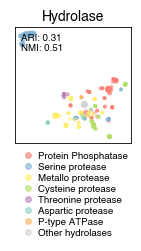

Kinase
protein_classification_level_3
Protein Kinase                       433
Protein kinase regulatory subunit     16
Name: count, dtype: int64


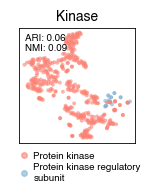

Family A G protein-coupled receptor
protein_classification_level_3
Peptide receptor (family A GPCR)           107
Small molecule receptor (family A GPCR)     99
Opsin                                        4
Name: count, dtype: int64


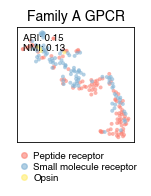

Reader
protein_classification_level_3
Methyl-lysine/arginine binding protein    65
Plant homeodomain                         51
Bromodomain                               25
YEATS domain                               4
Methyl-CpG-binding domain                  2
Name: count, dtype: int64


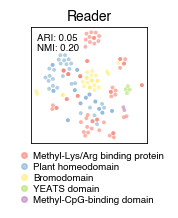

Electrochemical transporter
protein_classification_level_3
SLC superfamily of solute carriers               119
Mitochondrial pyruvate carrier family              1
Vesicular neurotransmitter transporter family      1
Name: count, dtype: int64


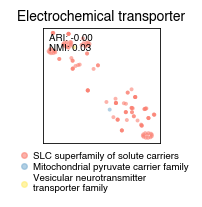

Voltage-gated ion channel
protein_classification_level_3
Potassium channels                      47
Transient receptor potential channel    22
Voltage-gated sodium channel            10
Voltage-gated calcium channel            9
Cyclic nucleotide-regulated channel      4
CatSper and Two-Pore channels            1
Name: count, dtype: int64


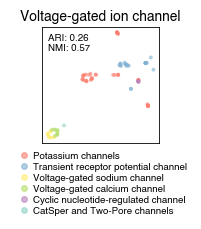

Ligand-gated ion channel
protein_classification_level_3
Ionotropic glutamate receptor       14
GABA-A receptor                     12
Nicotinic acetylcholine receptor     8
P2X receptor                         7
Glycine receptor                     3
Ryanodine receptor                   3
Epithelial sodium channel            3
5HT3 receptor                        2
Acid-sensing ion channel             2
IP3 receptor                         2
Name: count, dtype: int64


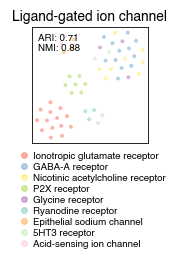

Primary active transporter
protein_classification_level_3
ATP-binding cassette                            20
F-type and V-type ATPases                       12
P-type ATPase                                    6
Oxidoreduction-driven transporters               2
Endoplasmic reticular retrotranslocon family     1
Name: count, dtype: int64


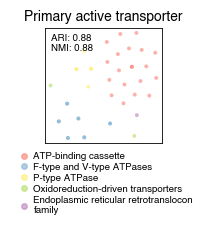

Writer
protein_classification_level_3
Protein methyltransferase    25
DNA methyltransferase         5
Histone acetyltransferase     2
Name: count, dtype: int64


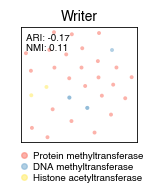

Eraser
protein_classification_level_3
Histone deacetylase    18
Lysine demethylase     11
Name: count, dtype: int64


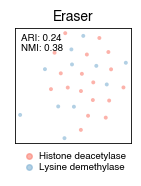

In [ ]:
cat_with_others = []
for category in query_class:
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    subset_with_tsne = add_tsne_features_to_df(subset, reps, perplexity=28)

    sub_categories = list(subset_with_tsne[category_col].value_counts().index)
    print(category)
    print(subset_with_tsne[category_col].value_counts())
    
    default_classes = ['Phosphodiesterase 4']
    sub_categories_tmp = sub_categories
    for sub_cat in sub_categories_tmp:
        if sub_cat in default_classes:
            sub_categories.remove(sub_cat)
            cat_with_others.append(category)
    cat_with_others = list(set(cat_with_others))

    topk = 7 if category == 'Hydrolase' else None
    if topk is not None:  sub_categories = sub_categories[:topk]

    n_categories = len(sub_categories)

    palette = sns.color_palette(['#fb8072', '#80b1d3', '#ffed6f','#b3de69', '#bc80bd','#8dd3c7', '#fdb462', '#ccebc5', '#fccde5'])
    category_to_color = {category: color for category, color in zip(sub_categories, palette)}
    subset_with_tsne['color'] = subset_with_tsne.apply(lambda row: category_to_color.get(row[category_col], 'lightgrey'), axis=1)
    subset_with_tsne['plot rank'] = [1+sub_categories.index(x) if (x in sub_categories) else 0 for x in list(subset_with_tsne[category_col])]
    subset_with_tsne = subset_with_tsne.sort_values(by=['plot rank']) 


    plt.figure(figsize=(1.5, 1.5)) 
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')  
        spine.set_linewidth(0.6)      
    plt.scatter(
            subset_with_tsne['t-SNE_1'], 
            subset_with_tsne['t-SNE_2'], 
            c=subset_with_tsne['color'], 
            alpha=0.6, 
            s=8, 
            linewidths=0.0,
            )
    
    handles = []
    labels = []
    abbrs = {
        "Protein Kinase": "Protein kinase",
        "Protein kinase regulatory subunit": "Protein kinase regulatory\nsubunit",
        "Vesicular neurotransmitter transporter family": "Vesicular neurotransmitter\ntransporter family",
        "Methyl-lysine/arginine binding protein": "Methyl-Lys/Arg binding protein",
        "Endoplasmic reticular retrotranslocon family": "Endoplasmic reticular retrotranslocon\nfamily",
        "Peptide receptor (family A GPCR)": "Peptide receptor",
        "Small molecule receptor (family A GPCR)": "Small molecule receptor"
    }
    for cat, color in zip(sub_categories, palette):
        if cat in abbrs.keys():
            cat = abbrs[cat]
        handles.append(plt.Line2D([0], [0], 
                                  color=color, 
                                  marker='o', 
                                  linestyle='None', 
                                  linewidth=0.1,
                                  alpha=0.6,
                                  markersize=4,
                                  ))
        labels.append(cat)
    if category in cat_with_others:
        handles.append(plt.Line2D([0], [0], 
                                    color='lightgrey', 
                                    marker='o', 
                                    linestyle='None', 
                                    linewidth=0.1,
                                    alpha=0.6,
                                    markersize=4,
                                    ))
        labels.append('Other hydrolases')

    plt.legend(handles, 
                labels, 
                ncol=1,
                loc='upper center', 
                bbox_to_anchor=(0.5, 0), 
                fontsize=7,
                facecolor='white',
                handletextpad=0,
                frameon=False,
                labelspacing=0.2,
                columnspacing=0.2,
                )

    abbrs_title = {
        "Family A G protein-coupled receptor": "Family A GPCR",
    }
    if category in abbrs_title.keys():
        category = abbrs_title[category]

    plt.title(category, fontsize=10, pad=5)
    plt.xticks([])
    plt.yticks([])
    plt.tick_params(axis='x', which='both', pad=0) 
    plt.tick_params(axis='y', which='both', pad=0)  
    plt.xlabel('', fontsize=9, labelpad=-2)
    plt.ylabel('', fontsize=9, labelpad=-5)

    select_df = pc_df[pc_df[category_col].isin(sub_categories)]
    select_pros = list(select_df['UniProt Accessions'])
    labels_true = list(select_df[f'protein_classification_level_{level}'])
    X = [reps[x] for x in select_pros]

    kmeans = KMeans(n_clusters=n_categories, random_state=0).fit(X)
    labels_pred = kmeans.labels_

    ari_score = adjusted_rand_score(labels_true, labels_pred)
    nmi_score = normalized_mutual_info_score(labels_true, labels_pred)

    metric_df = pd.concat([metric_df, pd.DataFrame({
        'level': [level],
        'class': ['target'],
        'ARI': [ari_score],
        'NMI': [nmi_score]
    })], ignore_index=True)

    plt.text(0.05, 0.95, 
            f'ARI: {ari_score:.2f}\nNMI: {nmi_score:.2f}', 
            transform=plt.gca().transAxes, 
            fontsize=7, 
            verticalalignment='top', 
            )  
    
    plt.show()  # 显示图像

In [33]:
metric_df = metric_df.drop_duplicates()
metric_df

,level,class,ARI,NMI
0,1.0,target,0.254463,0.295204
1,2.0,target,0.245429,0.355301
2,2.0,target,0.337897,0.595562
3,2.0,target,0.040874,0.096025
4,2.0,target,0.117002,0.329000
5,2.0,target,0.545727,0.523098
6,3.0,target,0.260486,0.582695
7,3.0,target,0.059669,0.093022
8,3.0,target,0.151130,0.127651
9,3.0,target,0.053683,0.197634


### protein_classification_level_4

In [31]:
level = 4
category_col = f'protein_classification_level_{level}'


query_class = []
for category in list(pc_df[f'protein_classification_level_{level-1}'].value_counts().index):
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    if category in ['Nuclear hormone receptor subfamily 1']: continue
    if len(subset) > 30 and (len(subset[category_col].value_counts()) > 1):
        query_class.append(category)
        print(category, len(subset))


Protein Kinase 430
SLC superfamily of solute carriers 119
Peptide receptor (family A GPCR) 105
Small molecule receptor (family A GPCR) 98
Protein Phosphatase 76
Serine protease 68
Metallo protease 69
Methyl-lysine/arginine binding protein 65
Potassium channels 47
Cysteine protease 47


In [ ]:
categories = list(df[f'protein_classification_level_{level}'].value_counts().index)
counts = pc_df[category_col].value_counts().reindex(categories).fillna(0)

result_df = pd.DataFrame({
    'Category': counts.index,
    'Count': counts.values
})

result_df

,Category,Count
0,TK protein kinase group,84
1,CAMK protein kinase group,71
2,Short peptide receptor (family A GPCR),63
3,CMGC protein kinase group,58
4,Other protein kinase group,55
...,...,...
197,Cytochrome P450 family 27A,1
198,Phosphodiesterase 8B,1
199,Phosphodiesterase 1B,1
200,SLC35 family of nucleotide sugar transporters,1


Current font settings: ['Helvetica']
Protein Kinase
protein_classification_level_4
TK protein kinase group          84
CAMK protein kinase group        71
CMGC protein kinase group        58
Other protein kinase group       55
AGC protein kinase group         54
STE protein kinase group         45
TKL protein kinase group         37
Atypical protein kinase group    16
CK1 protein kinase group         10
Name: count, dtype: int64


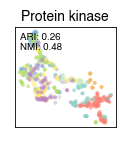

SLC superfamily of solute carriers
protein_classification_level_4
SLC06 neurotransmitter transporter family                                 13
SLC22 family of organic cation and anion transporters                     12
SLC21/SLCO family of organic anion transporting polypeptides               9
SLC02 family of hexose and sugar alcohol transporters                      8
SLC28 and SLC29 families of nucleoside transporters                        6
SLC05 family of sodium-dependent glucose transporters                      5
SLC27 family of fatty acid transporters                                    4
SLC12 family of cation-coupled chloride transporters                       4
SLC01 family of amino acid transporters                                    4
SLC09 family of sodium/hydrogen exchangers                                 4
SLC25 family of mitochondrial transporters                                 4
SLC16 family of monocarboxylate transporters                               4
SLC03 and 

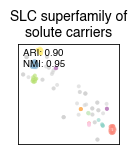

Peptide receptor (family A GPCR)
protein_classification_level_4
Short peptide receptor (family A GPCR)            63
Chemokine receptor                                23
Protease-activated receptor                        4
Relaxin-like peptide receptor (family A GPCR)      4
Glycohormone receptor                              3
Chemokine receptor-like                            2
N-formyl methionyl peptide receptor                2
Anaphylatoxin receptor family                      2
Peptide growth factor receptor (family A GPCR)     2
Name: count, dtype: int64


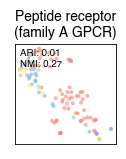

Small molecule receptor (family A GPCR)
protein_classification_level_4
Monoamine receptor                               40
Lipid-like ligand receptor (family A GPCR)       38
Nucleotide-like receptor (family A GPCR)         12
Carboxylic acid receptor                          6
Monoamine-derivative receptor (family A GPCR)     2
Name: count, dtype: int64


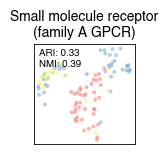

Protein Phosphatase
protein_classification_level_4
Tyrosine protein phosphatase                     31
Serine/threonine protein phosphatase             16
Serine/threonine/tyrosine protein phosphatase    15
Protein phosphatase regulatory subunit           13
Serine protein phosphatase                        1
Name: count, dtype: int64


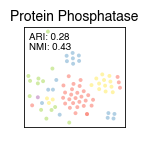

Serine protease
protein_classification_level_4
Serine protease PA clan    46
Serine protease SC clan    12
Serine protease SB clan    10
Name: count, dtype: int64


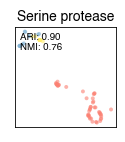

Metallo protease
protein_classification_level_4
Metallo protease MAM clan    34
Metallo protease MAE clan    15
Metallo protease MC clan      9
Metallo protease MG clan      5
Metallo protease MH clan      3
Metallo protease MP clan      1
Metallo protease MJ clan      1
Metallo protease MF clan      1
Name: count, dtype: int64


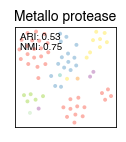

Methyl-lysine/arginine binding protein
protein_classification_level_4
Chromodomain    22
Tudor domain    19
PWWP domain     13
WDR domain       6
MBT domain       5
Name: count, dtype: int64


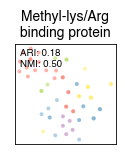

Potassium channels
protein_classification_level_4
Voltage-gated potassium channel          24
Inwardly rectifying potassium channel    10
Two-pore domain potassium channel         8
Calcium-activated potassium channel       5
Name: count, dtype: int64


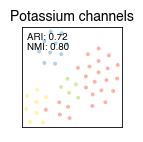

Cysteine protease
protein_classification_level_4
Cysteine protease CA clan     29
Cysteine protease CD clan     12
Cysteine protease CE clan      5
Cysteine protease PCC clan     1
Name: count, dtype: int64


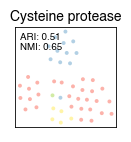

In [ ]:
cat_with_others = ['Protein Kinase', 'SLC superfamily of solute carriers']
for category in query_class:
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    subset_with_tsne = add_tsne_features_to_df(subset, reps, perplexity=30)

    sub_categories = list(subset_with_tsne[category_col].value_counts().index)
    print(category)
    print(subset_with_tsne[category_col].value_counts())

    default_classes = ['Other protein kinase group']
    sub_categories_tmp = sub_categories
    for sub_cat in sub_categories_tmp:
        if sub_cat in default_classes:
            sub_categories.remove(sub_cat)
            cat_with_others.append(category)

    cat_with_others = list(set(cat_with_others))

    topk = 10 if 'SLC' in category else None
    if topk is not None:  sub_categories = sub_categories[:topk]

    n_categories = len(sub_categories)

    palette = sns.color_palette(['#fb8072', '#80b1d3', '#ffed6f','#b3de69', '#bc80bd','#8dd3c7', '#fdb462', '#ccebc5', '#fccde5'])
    category_to_color = {category: color for category, color in zip(sub_categories, palette)}
    subset_with_tsne['color'] = subset_with_tsne.apply(lambda row: category_to_color.get(row[category_col], 'lightgrey'), axis=1)
    subset_with_tsne['plot rank'] = [1+sub_categories.index(x) if (x in sub_categories) else 0 for x in list(subset_with_tsne[category_col])]
    subset_with_tsne = subset_with_tsne.sort_values(by=['plot rank']) 


    plt.figure(figsize=(1.3, 1.3))
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')  
        spine.set_linewidth(0.6)      

    plt.scatter(
            subset_with_tsne['t-SNE_1'], 
            subset_with_tsne['t-SNE_2'], 
            c=subset_with_tsne['color'], 
            alpha=0.6, 
            s=8, 
            edgecolors='gray', 
            linewidths=0.0,
            )
    

    handles = []
    labels = []
    abbrs = {
        "TK protein kinase group": "TK",
        "CAMK protein kinase group": "CAMK",
        "CMGC protein kinase group": "CMGC",
        "Other protein kinase group": "Other protein kinases",
        "AGC protein kinase group": "AGC",
        "STE protein kinase group": "STE",
        "TKL protein kinase group": "TKL",
        "Atypical protein kinase group": "Atypical kinase",
        "CK1 protein kinase group": "CK1",

        "SLC06 neurotransmitter transporter family": "SLC06",
        "SLC22 family of organic cation and anion transporters": "SLC22",
        "SLC21/SLCO family of organic anion transporting polypeptides": "SLC21/SLCO",
        "SLC02 family of hexose and sugar alcohol transporters": "SLC02",
        "SLC28 and SLC29 families of nucleoside transporters": "SLC28/SLC29",
        "SLC05 family of sodium-dependent glucose transporters": "SLC05",
        "SLC12 family of cation-coupled chloride transporters": "SLC12",
        "SLC27 family of fatty acid transporters": "SLC27",
        "SLC25 family of mitochondrial transporters": "SLC25",
        "SLC01 family of amino acid transporters": "SLC01",
        "SLC16 family of monocarboxylate transporters": "SLC16",
        "SLC09 family of sodium/hydrogen exchangers": "SLC09",
        "SLC26 family of anion exchangers": "SLC26",
        "SLC13 family of sodium-dependent sulphate/carboxylate transporters": "SLC13",
        "SLC03 and SLC07 families of heteromeric amino acid transporters (HATs)": "SLC03/SLC07",
        "SLC34 family of sodium phosphate co-transporters": "SLC34",
        "SLC18 family of vesicular amine transporters": "SLC18",
        "SLC10 family of sodium-bile acid co-transporters": "SLC10",
        "SLC19 family of vitamin transporters": "SLC19",
        "SLC20 family of sodium-dependent phosphate transporters": "SLC20",
        "SLC15 family of peptide transporters": "SLC15",
        "SLC11 family of proton-coupled metal ion transporters": "SLC11",
        "SLC17 phosphate and organic anion transporter family": "SLC17",
        "SLC47 family of multidrug and toxin extrusion transporters": "SLC47",
        "SLC08 family of sodium/calcium exchangers": "SLC08",
        "SLC35 family of nucleotide sugar transporters": "SLC35",
        "SLC40 iron transporter": "SLC40",
        "SLC14 family of facilitative urea transporters": "SLC14",
        "SLC23 family of ascorbic acid transporters": "SLC23",
        "SLC33 acetylCoA transporter": "SLC33",
        "SLC43 family of large neutral amino acid transporters": "SLC43",
        "SLC46 family of folate transporters": "SLC46",
        "SLC51 family of steroid-derived molecule transporters": "SLC51",
        "SLC39 family of metal ion transporters": "SLC39",
        "SLC36 family of proton-coupled amino acid transporters": "SLC36",
        "SLC37 family of phosphosugar/phosphate exchangers": "SLC37",

        "Short peptide receptor (family A GPCR)": "Short peptide receptor",
        "Chemokine receptor": "Chemokine receptor",
        "Protease-activated receptor": "Protease-activated receptor",
        "Relaxin-like peptide receptor (family A GPCR)": "Relaxin-like peptide receptor",
        "Glycohormone receptor": "Glycohormone receptor",
        "N-formyl methionyl peptide receptor": "FMMP receptor",
        "Anaphylatoxin receptor family": "Anaphylatoxin receptor",
        "Peptide growth factor receptor (family A GPCR)": "Peptide growth factor receptor",
        "Chemokine receptor-like": "Chemokine receptor-like",
        "Small molecule receptor (family A GPCR)": "Small molecule receptor",
        "Monoamine receptor": "Monoamine receptor",
        "Lipid-like ligand receptor (family A GPCR)": "Lipid-like ligand receptor",
        "Nucleotide-like receptor (family A GPCR)": "Nucleotide-like receptor",
        "Carboxylic acid receptor": "Carboxylic acid receptor",
        "Monoamine-derivative receptor (family A GPCR)": "Monoamine-derivative receptor",
        "Tyrosine protein phosphatase": "Protein Tyr phosphatase",
        "Serine/threonine protein phosphatase": "Protein Ser/Thr phosphatase",
        "Serine/threonine/tyrosine protein phosphatase": "Protein Ser/Thr/Tyr phosphatase",
        "Protein phosphatase regulatory subunit": "Protein phosphatase regulatory\nsubunit",
        "Serine protein phosphatase": "Protein Ser phosphatase",
        "Serine protease PA clan": "PA clan",
        "Serine protease SC clan": "SC clan",
        "Serine protease SB clan": "SB clan",

        "Metallo protease MAM clan": "MAM clan",
        "Metallo protease MAE clan": "MAE clan",
        "Metallo protease MC clan": "MC clan",
        "Metallo protease MG clan": "MG clan",
        "Metallo protease MH clan": "MH clan",
        "Metallo protease MF clan": "MF clan",
        "Metallo protease MP clan": "MP clan",
        "Metallo protease MJ clan": "MJ clan",

        "Cysteine protease CA clan": "CA clan",
        "Cysteine protease CD clan": "CD clan",
        "Cysteine protease CE clan": "CE clan",
        "Cysteine protease PCC clan": "PCC clan",
        
        "Voltage-gated potassium channel": "VGK channel",
        "Inwardly rectifying potassium channel": "Kir channel",
        "Two-pore domain potassium channel": "K2P channel",
        "Calcium-activated potassium channel": "K$_{Ca}$ channel"
    }
    for cat, color in zip(sub_categories, palette):
        if cat in abbrs.keys():
            cat = abbrs[cat]
        handles.append(plt.Line2D([0], [0], 
                                  color=color, 
                                  marker='o', 
                                  linestyle='None', 
                                  linewidth=0.1,
                                  alpha=0.6,
                                  markersize=4,
                                  ))
        labels.append(cat)
    if category in cat_with_others:
        handles.append(plt.Line2D([0], [0], 
                                    color='lightgrey', 
                                    marker='o', 
                                    linestyle='None', 
                                    linewidth=0.1,
                                    alpha=0.6,
                                    markersize=4,
                                    ))
        labels.append('Others')

    abbrs_title = {
        "Protein Kinase": "Protein kinase",
        "SLC superfamily of solute carriers": "SLC superfamily of\nsolute carriers",
        "Peptide receptor (family A GPCR)": "Peptide receptor\n(family A GPCR)",
        "Small molecule receptor (family A GPCR)": "Small molecule receptor\n(family A GPCR)",
        "Methyl-lysine/arginine binding protein": "Methyl-lys/Arg\nbinding protein",
    }
    if category in abbrs_title.keys():
        category = abbrs_title[category]

    plt.title(category, fontsize=10, pad=5)
    plt.xticks([])
    plt.yticks([])
    plt.tick_params(axis='x', which='both', pad=0) 
    plt.tick_params(axis='y', which='both', pad=0)  
    plt.xlabel('', fontsize=9, labelpad=-2)
    plt.ylabel('', fontsize=9, labelpad=-5)


    select_df = pc_df[pc_df[category_col].isin(sub_categories)]
    select_pros = list(select_df['UniProt Accessions'])
    labels_true = list(select_df[f'protein_classification_level_{level}'])
    X = [reps[x] for x in select_pros]

    kmeans = KMeans(n_clusters=n_categories, random_state=0).fit(X)
    labels_pred = kmeans.labels_

    ari_score = adjusted_rand_score(labels_true, labels_pred)
    nmi_score = normalized_mutual_info_score(labels_true, labels_pred)

    metric_df = pd.concat([metric_df, pd.DataFrame({
        'level': [level],
        'class': ['target'],
        'ARI': [ari_score],
        'NMI': [nmi_score]
    })], ignore_index=True)


    plt.text(0.05, 0.95, 
            f'ARI: {ari_score:.2f}\nNMI: {nmi_score:.2f}', 
            transform=plt.gca().transAxes, 
            fontsize=7, 
            verticalalignment='top', 
            )

    category = category.replace("/", "_")
    category = category.replace("\n", " ") 
   
    plt.show()  # 显示图像

In [37]:
metric_df = metric_df.drop_duplicates()
metric_df

,level,class,ARI,NMI
0,1.0,target,0.254463,0.295204
1,2.0,target,0.245429,0.355301
2,2.0,target,0.337897,0.595562
3,2.0,target,0.040874,0.096025
4,2.0,target,0.117002,0.329000
5,2.0,target,0.545727,0.523098
6,3.0,target,0.260486,0.582695
7,3.0,target,0.059669,0.093022
8,3.0,target,0.151130,0.127651
9,3.0,target,0.053683,0.197634


In [44]:
metric_df['level'].value_counts()

level
3.0    10
4.0    10
2.0     5
1.0     1
Name: count, dtype: int64

### protein_classification_level_5

In [42]:
level = 5
category_col = f'protein_classification_level_{level}'

query_class = []
for category in list(pc_df[f'protein_classification_level_{level-1}'].value_counts().index):
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    if category in ['Nuclear hormone receptor subfamily 1']: continue
    if len(subset) > 30 and (len(subset[category_col].value_counts()) > 1):
        query_class.append(category)
        print(category, len(subset))


TK protein kinase group 83
CAMK protein kinase group 69
Short peptide receptor (family A GPCR) 63
CMGC protein kinase group 55
Other protein kinase group 52
AGC protein kinase group 53
STE protein kinase group 44
Monoamine receptor 40
Lipid-like ligand receptor (family A GPCR) 36
TKL protein kinase group 34
Metallo protease MAM clan 34


In [45]:
categories = list(df[f'protein_classification_level_{level}'].value_counts().index)
counts = pc_df[category_col].value_counts().reindex(categories).fillna(0)

result_df = pd.DataFrame({
    'Category': counts.index,
    'Count': counts.values
})

pd.set_option('display.max_rows', None)
result_df

,Category,Count
0,Serine protease S1A subfamily,46
1,STE protein kinase STE20 family,27
2,CAMK protein kinase CAMK1 family,22
3,Metallo protease M10A subfamily,19
4,CMGC protein kinase CDK family,17
5,Cysteine protease C19 family,15
6,CMGC protein kinase MAPK family,14
7,CC chemokine receptor,13
8,TKL protein kinase STKR family,12
9,Receptor tyrosine-protein phosphatase,12


Current font settings: ['Helvetica']
TK protein kinase group
protein_classification_level_5
Tyrosine protein kinase Eph family      12
Tyrosine protein kinase Src family      11
Tyrosine protein kinase JakB family      8
Tyrosine protein kinase PDGFR family     5
Tyrosine protein kinase Tec family       5
Tyrosine protein kinase FGFR family      4
Tyrosine protein kinase EGFR family      4
Tyrosine protein kinase Trk family       3
Tyrosine protein kinase Axl family       3
Tyrosine protein kinase VEGFR family     3
Tyrosine protein kinase InsR family      3
Tyrosine protein kinase Abl family       2
Tyrosine protein kinase Syk family       2
Tyrosine protein kinase Fer family       2
Tyrosine protein kinase Met family       2
Tyrosine protein kinase Tie family       2
Tyrosine protein kinase DDR family       2
Tyrosine protein kinase Fak family       2
Tyrosine protein kinase Ack family       2
Tyrosine protein kinase Csk family       2
Tyrosine protein kinase Musk family      1
Tyros

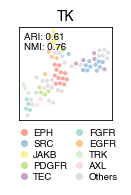

CAMK protein kinase group
protein_classification_level_5
CAMK protein kinase CAMK1 family      22
CAMK protein kinase RSKb family       12
CAMK protein kinase DAPK family        5
CAMK protein kinase MAPKAPK family     5
CAMK protein kinase TSSK family        4
CAMK protein kinase MLCK family        4
CAMK protein kinase CAMK2 family       4
CAMK protein kinase PKD family         3
CAMK protein kinase DCAMK1 family      3
CAMK protein kinase PIM family         3
CAMK protein kinase PHk family         2
CAMK protein kinase RAD53 family       1
CAMK protein kinase unique family      1
Name: count, dtype: int64


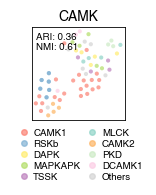

Short peptide receptor (family A GPCR)
protein_classification_level_5
Neuropeptide receptor                   6
Somatostatin receptor                   5
Melanocortin receptor                   5
Neuropeptide Y receptor                 4
Vasopressin and oxytocin receptor       4
Opioid receptor                         4
RF amide receptor                       4
Endothelin receptor                     3
Neurokinin receptor                     3
Galanin receptor                        3
GRP-related receptor                    3
Cholecystokinin receptor                2
MCH receptor                            2
Neurotensin receptor                    2
Orexin receptor                         2
Neuromedin U receptor                   2
Angiotensin receptor                    2
Bradykinin receptor                     2
Motilin receptor                        1
Adrenomedullin receptor                 1
Neuromedin receptor                     1
GnRH receptor                           1
Prolac

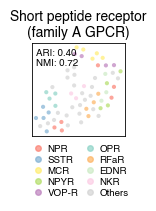

CMGC protein kinase group
protein_classification_level_5
CMGC protein kinase CDK family     17
CMGC protein kinase MAPK family    14
CMGC protein kinase DYRK family     9
CMGC protein kinase CDKL family     4
CMGC protein kinase CLK family      4
CMGC protein kinase SRPK family     3
CMGC protein kinase RCK family      2
CMGC protein kinase GSK family      2
Name: count, dtype: int64


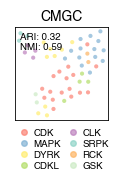

Other protein kinase group
protein_classification_level_5
Other protein kinase NEK family       11
Other protein kinase NAK family        4
Other protein kinase PLK family        4
Other protein kinase Wnk family        4
Other protein kinase ULK family        4
Other protein kinase PEK family        4
Other protein kinase AUR family        3
Other protein kinase WEE family        3
Other protein kinase CAMKK family      2
Other protein kinase CK2 family        2
Other protein kinase NKF1 family       2
Other protein kinase TLK family        2
Other protein kinase CDC7 family       1
Other protein kinase TTK family        1
Other protein kinase MOS family        1
Other protein kinase NKF4 family       1
Other protein kinase Haspin family     1
Other protein kinase TOPK family       1
Other protein kinase IKK family        1
Name: count, dtype: int64


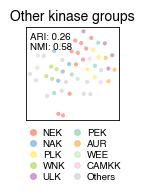

AGC protein kinase group
protein_classification_level_5
AGC protein kinase PKC family        9
AGC protein kinase GRK family        7
AGC protein kinase DMPK family       7
AGC protein kinase NDR family        4
AGC protein kinase MAST family       4
AGC protein kinase PKA family        4
AGC protein kinase PKN family        4
AGC protein kinase YANK family       3
AGC protein kinase SGK family        3
AGC protein kinase AKT family        3
AGC protein kinase RSK family        2
AGC protein kinase PKG family        2
AGC protein kinase PDK1 subfamily    1
Name: count, dtype: int64


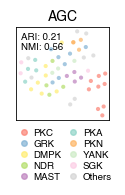

STE protein kinase group
protein_classification_level_5
STE protein kinase STE20 family     27
STE protein kinase STE11 family      9
STE protein kinase STE7 family       7
STE protein kinase unique family     1
Name: count, dtype: int64


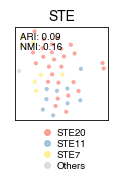

Monoamine receptor
protein_classification_level_5
Serotonin receptor        12
Adrenergic receptor        9
Acetylcholine receptor     5
Dopamine receptor          5
Trace amine receptor       5
Histamine receptor         4
Name: count, dtype: int64


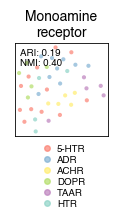

Lipid-like ligand receptor (family A GPCR)
protein_classification_level_5
EDG receptor                         11
Prostanoid receptor                   9
Leukotriene receptor                  6
Free fatty acid receptor              4
Cannabinoid receptor                  2
Steroid-like ligand receptor          2
PAF receptor                          1
Lysophosphatidylinositol receptor     1
Name: count, dtype: int64


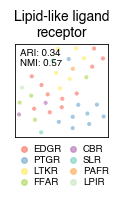

TKL protein kinase group
protein_classification_level_5
TKL protein kinase STKR family    12
TKL protein kinase MLK family      8
TKL protein kinase RIPK family     4
TKL protein kinase RAF family      3
TKL protein kinase IRAK family     3
TKL protein kinase LISK family     3
TKL protein kinase LRRK family     1
Name: count, dtype: int64


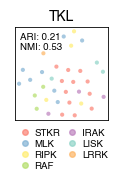

Metallo protease MAM clan
protein_classification_level_5
Metallo protease M10A subfamily    19
Metallo protease M12B subfamily    10
Metallo protease M12A subfamily     5
Name: count, dtype: int64


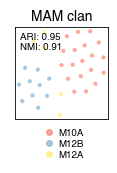

In [ ]:
cat_with_others = ['TK protein kinase group']
for category in query_class:
    subset = pc_df[pc_df.loc[:, f'protein_classification_level_{level-1}'] == category].dropna(subset=[category_col])
    subset_with_tsne = add_tsne_features_to_df(subset, reps, perplexity=25)

    sub_categories = list(subset_with_tsne[category_col].value_counts().index)
    print(category)
    print(subset_with_tsne[category_col].value_counts())

    default_classes = ['Other protein kinase group', 'STE protein kinase unique family']
    sub_categories_tmp = sub_categories
    for sub_cat in sub_categories_tmp:
        if sub_cat in default_classes:
            sub_categories.remove(sub_cat)
            cat_with_others.append(category)
    cat_with_others = list(set(cat_with_others))

    topk = 9
    if topk is not None and len(sub_categories) > topk:  
        sub_categories = sub_categories[:topk]
        cat_with_others.append(category)

    n_categories = len(sub_categories)
    palette = sns.color_palette(['#fb8072', '#80b1d3', '#ffed6f','#b3de69', '#bc80bd','#8dd3c7', '#fdb462', '#ccebc5', '#fccde5'])
    category_to_color = {category: color for category, color in zip(sub_categories, palette)}
    subset_with_tsne['color'] = subset_with_tsne.apply(lambda row: category_to_color.get(row[category_col], 'lightgrey'), axis=1)
    subset_with_tsne['plot rank'] = [1+sub_categories.index(x) if (x in sub_categories) else 0 for x in list(subset_with_tsne[category_col])]
    subset_with_tsne = subset_with_tsne.sort_values(by=['plot rank']) 


    plt.figure(figsize=(1.2, 1.2)) 
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')  
        spine.set_linewidth(0.6)      

    plt.scatter(
            subset_with_tsne['t-SNE_1'], 
            subset_with_tsne['t-SNE_2'], 
            c=subset_with_tsne['color'], 
            alpha=0.7, 
            s=9, 
            edgecolors='gray', 
            linewidths=0.0,
            )

    handles = []
    labels = []
    abbrs = {
        "Tyrosine protein kinase Eph family": "EPH",
        "Tyrosine protein kinase Src family": "SRC",
        "Tyrosine protein kinase JakB family": "JAKB",
        "Tyrosine protein kinase Tec family": "TEC",
        "Tyrosine protein kinase PDGFR family": "PDGFR",
        "Tyrosine protein kinase FGFR family": "FGFR",
        "Tyrosine protein kinase EGFR family": "EGFR",
        "Tyrosine protein kinase InsR family": "INSR",
        "Tyrosine protein kinase VEGFR family": "VEGFR",
        "Tyrosine protein kinase Trk family": "TRK",
        "Tyrosine protein kinase Axl family": "AXL",
        "Tyrosine protein kinase Csk family": "CSK",
        "Tyrosine protein kinase Tie family": "TIE",
        "Tyrosine protein kinase Fer family": "FER",
        "Tyrosine protein kinase Fak family": "FAK",
        "Tyrosine protein kinase DDR family": "DDR",
        "Tyrosine protein kinase Ack family": "ACK",
        "Tyrosine protein kinase Met family": "MET",
        "Tyrosine protein kinase Syk family": "SYK",
        "Tyrosine protein kinase Abl family": "ABL",
        "Tyrosine protein kinase Alk family": "ALK",
        "Tyrosine protein kinase Musk family": "MUSK",
        "Tyrosine protein kinase Sev family": "SEV",
        "Tyrosine protein kinase Ret family": "RET",

        "CAMK protein kinase CAMK1 family": "CAMK1",
        "CAMK protein kinase RSKb family": "RSKb",
        "CAMK protein kinase MAPKAPK family": "MAPKAPK",
        "CAMK protein kinase DAPK family": "DAPK",
        "CAMK protein kinase CAMK2 family": "CAMK2",
        "CAMK protein kinase MLCK family": "MLCK",
        "CAMK protein kinase TSSK family": "TSSK",
        "CAMK protein kinase DCAMK1 family": "DCAMK1",
        "CAMK protein kinase PKD family": "PKD",
        "CAMK protein kinase PIM family": "PIM",
        "CAMK protein kinase PHk family": "PHk",
        "CAMK protein kinase unique family": "Unique CAMK",
        "CAMK protein kinase RAD53 family": "RAD53",

        "CMGC protein kinase group": "CMGC",
        "CMGC protein kinase CDK family": "CDK",
        "CMGC protein kinase MAPK family": "MAPK",
        "CMGC protein kinase DYRK family": "DYRK",
        "CMGC protein kinase CLK family": "CLK",
        "CMGC protein kinase CDKL family": "CDKL",
        "CMGC protein kinase SRPK family": "SRPK",
        "CMGC protein kinase RCK family": "RCK",
        "CMGC protein kinase GSK family": "GSK",

        "Neuropeptide receptor": "NPR",
        "Somatostatin receptor": "SSTR",
        "Melanocortin receptor": "MCR",
        "Neuropeptide Y receptor": "NPYR",
        "Vasopressin and oxytocin receptor": "VOP-R",
        "Opioid receptor": "OPR",
        "RF amide receptor": "RFaR",
        "Neurokinin receptor": "NKR",
        "Endothelin receptor": "EDNR",
        "Galanin receptor": "GALR",
        "GRP-related receptor": "GRP-R",
        "Angiotensin receptor": "AGTR",
        "Neuromedin U receptor": "NMBR",
        "Neurotensin receptor": "NTSR",
        "Bradykinin receptor": "BKR",
        "MCH receptor": "MCHR",
        "Cholecystokinin receptor": "CCKR",
        "Orexin receptor": "OXR",
        "Adrenomedullin receptor": "ADMR",
        "Prolactin-releasing peptide receptor": "PRLR-PR",
        "GnRH receptor": "GnRHR",
        "Neuromedin receptor": "NMDR",
        "Motilin receptor": "MOTR",

        "CMGC protein kinase CDK family": "CDK",
        "CMGC protein kinase MAPK family": "MAPK",
        "CMGC protein kinase DYRK family": "DYRK",
        "CMGC protein kinase CLK family": "CLK",
        "CMGC protein kinase CDKL family": "CDKL",
        "CMGC protein kinase SRPK family": "SRPK",
        "CMGC protein kinase RCK family": "RCK",
        "CMGC protein kinase GSK family": "GSK",

        "Other protein kinase NEK family": "NEK",
        "Other protein kinase NAK family": "NAK",
        "Other protein kinase Wnk family": "WNK",
        "Other protein kinase ULK family": "ULK",
        "Other protein kinase PEK family": "PEK",
        "Other protein kinase PLK family": "PLK",
        "Other protein kinase WEE family": "WEE",
        "Other protein kinase AUR family": "AUR",
        "Other protein kinase TLK family": "TLK",
        "Other protein kinase CK2 family": "CK2",
        "Other protein kinase CAMKK family": "CAMKK",
        "Other protein kinase NKF1 family": "NKF1",
        "Other protein kinase IKK family": "IKK",
        "Other protein kinase Haspin family": "HASPIN",
        "Other protein kinase TTK family": "TTK",
        "Other protein kinase NKF4 family": "NKF4",
        "Other protein kinase TOPK family": "TOPK",
        "Other protein kinase MOS family": "MOS",
        "Other protein kinase CDC7 family": "CDC7",

        "AGC protein kinase PKC family": "PKC",
        "AGC protein kinase GRK family": "GRK",
        "AGC protein kinase DMPK family": "DMPK",
        "AGC protein kinase PKA family": "PKA",
        "AGC protein kinase MAST family": "MAST",
        "AGC protein kinase NDR family": "NDR",
        "AGC protein kinase PKN family": "PKN",
        "AGC protein kinase YANK family": "YANK",
        "AGC protein kinase SGK family": "SGK",
        "AGC protein kinase AKT family": "AKT",
        "AGC protein kinase PKG family": "PKG",
        "AGC protein kinase RSK family": "RSK",
        "AGC protein kinase PDK1 subfamily": "PDK1",

        "STE protein kinase STE20 family": "STE20",
        "STE protein kinase STE11 family": "STE11",
        "STE protein kinase STE7 family": "STE7",
        "STE protein kinase unique family": "Unique STE",

        "Serotonin receptor": "5-HTR",
        "Adrenergic receptor": "ADR",
        "Trace amine receptor": "TAAR",
        "Dopamine receptor": "DOPR",
        "Acetylcholine receptor": "ACHR",
        "Histamine receptor": "HTR",

        "EDG receptor": "EDGR",
        "Prostanoid receptor": "PTGR",
        "Leukotriene receptor": "LTKR",
        "Free fatty acid receptor": "FFAR",
        "Cannabinoid receptor": "CBR",
        "Steroid-like ligand receptor": "SLR",
        "Lysophosphatidylinositol receptor": "LPIR",
        "PAF receptor": "PAFR",

        "TKL protein kinase STKR family": "STKR",
        "TKL protein kinase MLK family": "MLK",
        "TKL protein kinase RIPK family": "RIPK",  # [^61^]
        "TKL protein kinase LISK family": "LISK",
        "TKL protein kinase IRAK family": "IRAK",
        "TKL protein kinase RAF family": "RAF",
        "TKL protein kinase LRRK family": "LRRK",  # [^68^]

        "Metallo protease M10A subfamily": "M10A",
        "Metallo protease M12B subfamily": "M12B",
        "Metallo protease M12A subfamily": "M12A",
    }
    for cat, color in zip(sub_categories, palette):
        if cat in abbrs.keys():
            cat = abbrs[cat]
        handles.append(plt.Line2D([0], [0], 
                                  color=color, 
                                  marker='o', 
                                  linestyle='None', 
                                  linewidth=0.1,
                                  alpha=0.7,
                                  markersize=4,
                                  ))
        labels.append(cat)
    if category in cat_with_others:
        handles.append(plt.Line2D([0], [0], 
                                    color='lightgrey', 
                                    marker='o', 
                                    linestyle='None', 
                                    linewidth=0.1,
                                    alpha=0.7,
                                    markersize=4,
                                    ))
        labels.append('Others')
        
    plt.legend(handles, 
                labels, 
                ncol=1 if len(sub_categories)<7 else 2,
                loc='upper center', 
                bbox_to_anchor=(0.5, 0), 
                fontsize=7,
                facecolor='white',
                handletextpad=0,
                frameon=False,
                labelspacing=0.2,
                columnspacing=0.2,
                )

    abbrs_title = {
        "TK protein kinase group": "TK",
        "CAMK protein kinase group": "CAMK",
        "Short peptide receptor (family A GPCR)": "Short peptide receptor\n(family A GPCR)",
        "CMGC protein kinase group": "CMGC",
        "Other protein kinase group": "Other kinase groups",
        "AGC protein kinase group": "AGC",
        "STE protein kinase group": "STE",
        "Monoamine receptor": "Monoamine\nreceptor",
        "Lipid-like ligand receptor (family A GPCR)": "Lipid-like ligand\nreceptor",
        "TKL protein kinase group": "TKL",
        "Metallo protease MAM clan": "MAM clan"
    }
    if category in abbrs_title.keys():
        category = abbrs_title[category]

    plt.title(category, fontsize=10, pad=5)
    plt.xticks([])
    plt.yticks([])
    plt.tick_params(axis='x', which='both', pad=0) 
    plt.tick_params(axis='y', which='both', pad=0)
    plt.xlabel('', fontsize=9, labelpad=-2)
    plt.ylabel('', fontsize=9, labelpad=-5)


    select_df = pc_df[pc_df[category_col].isin(sub_categories)]
    select_pros = list(select_df['UniProt Accessions'])
    labels_true = list(select_df[f'protein_classification_level_{level}'])
    X = [reps[x] for x in select_pros]

    kmeans = KMeans(n_clusters=n_categories, random_state=0).fit(X)
    labels_pred = kmeans.labels_

    ari_score = adjusted_rand_score(labels_true, labels_pred)
    nmi_score = normalized_mutual_info_score(labels_true, labels_pred)

    metric_df = pd.concat([metric_df, pd.DataFrame({
        'level': [level],
        'class': ['target'],
        'ARI': [ari_score],
        'NMI': [nmi_score]
    })], ignore_index=True)

    plt.text(0.05, 0.95, 
            f'ARI: {ari_score:.2f}\nNMI: {nmi_score:.2f}', 
            transform=plt.gca().transAxes, 
            fontsize=7, 
            verticalalignment='top', 
            )

    category = category.replace("/", "_")
    category = category.replace("\n", " ")

    plt.show()  

In [49]:
metric_df = metric_df.drop_duplicates()
metric_df

,level,class,ARI,NMI
0,1.0,target,0.254463,0.295204
1,2.0,target,0.245429,0.355301
2,2.0,target,0.337897,0.595562
3,2.0,target,0.040874,0.096025
4,2.0,target,0.117002,0.329000
5,2.0,target,0.545727,0.523098
6,4.0,target,0.262566,0.477118
7,4.0,target,0.902181,0.945834
8,4.0,target,0.014132,0.274192
9,4.0,target,0.331298,0.388559


In [ ]:
metric_df.to_csv('../results/unipert_target_level_clustering_results.csv')

In [ ]:
import pandas as pd
metric_df = pd.read_csv('../results/unipert_target_level_clustering_results.csv', index_col=0)
metric_df.describe()

,level,ARI,NMI
count,37.000000,37.000000,37.000000
mean,3.675676,0.340698,0.495484
std,1.131716,0.277771,0.252937
min,1.000000,-0.169652,0.025417
25%,3.000000,0.175465,0.329000
50%,4.000000,0.264612,0.523098
75%,5.000000,0.508106,0.647305
max,5.000000,0.948354,0.945834
